Khi accuracy đánh lừa

In [ ]:
# -*- coding: utf-8 -*-
"""Bước 1: thấy accuracy đánh lừa trên dữ liệu lệch lớp.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import pandas as pd
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
print("Kich thuoc bang:", df.shape)
print(df.head())
print()
print("So sinh vien moi lop:")
print(df["bo_hoc"].value_counts().to_string())
print(f"Ty le bo hoc: {df['bo_hoc'].mean():.3f}")
print()

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
# stratify=y giữ đúng tỷ lệ bỏ học ở cả tập học lẫn tập kiểm tra
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)
print(f"Tap kiem tra: {len(y_te)} ban, {y_te.sum()} ban bo hoc")
print()

# Mô hình lười: ai cũng đoán là lớp đông nhất
luoi = DummyClassifier(strategy="most_frequent").fit(X_tr, y_tr)
du_luoi = luoi.predict(X_te)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
du_lr = lr.predict(X_te)

for ten, du in [("Mo hinh luoi", du_luoi), ("Hoi quy logistic", du_lr)]:
    acc = accuracy_score(y_te, du)
    tim_ra = ((du == 1) & (y_te == 1)).sum()
    print(f"{ten:17s} accuracy {acc:.4f}, "
          f"tim ra {tim_ra} tren {y_te.sum()} ban bo hoc")

Kich thuoc bang: (1200, 5)
   diem_tb  so_buoi_vang  tin_chi_no  gio_lam_them  bo_hoc
0      8.0             3           0             0       0
1      8.9             5           1             7       0
2      3.3             3           1             4       0
3      6.4             3           0             7       0
4      7.9             3           5            23       0

So sinh vien moi lop:
bo_hoc
0    1081
1     119
Ty le bo hoc: 0.099

Tap kiem tra: 300 ban, 30 ban bo hoc

Mo hinh luoi      accuracy 0.9000, tim ra 0 tren 30 ban bo hoc
Hoi quy logistic  accuracy 0.9467, tim ra 17 tren 30 ban bo hoc


Ma trận nhầm lẫn

In [ ]:
# -*- coding: utf-8 -*-
"""Bước 2: tự đếm bốn ô của ma trận nhầm lẫn, rồi so với thư viện."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
that = y_te.to_numpy()

# Tự đếm: mỗi ô là một cặp (nhãn thật, nhãn đoán)
tp = np.sum((that == 1) & (du == 1))
fp = np.sum((that == 0) & (du == 1))
fn = np.sum((that == 1) & (du == 0))
tn = np.sum((that == 0) & (du == 0))
print("Tu dem:")
print(f"  TP = {tp} (doan bo hoc, dung la bo hoc)")
print(f"  FP = {fp} (bao dong nham)")
print(f"  FN = {fn} (bo sot)")
print(f"  TN = {tn} (doan khong bo, dung la khong bo)")
print(f"  Tong = {tp + fp + fn + tn}")
print()

m = confusion_matrix(that, du)
print("confusion_matrix cua scikit-learn:")
print(m)
print("Thu tu khi trai ra: TN, FP, FN, TP =", m.ravel())
print()

acc = (tp + tn) / (tp + fp + fn + tn)
print(f"Accuracy tinh tu bon o: ({tp} + {tn}) / {len(that)} = {acc:.4f}")
print(f"So ban bi bao co nguy co: TP + FP = {tp + fp}")

Tu dem:
  TP = 17 (doan bo hoc, dung la bo hoc)
  FP = 3 (bao dong nham)
  FN = 13 (bo sot)
  TN = 267 (doan khong bo, dung la khong bo)
  Tong = 300

confusion_matrix cua scikit-learn:
[[267   3]
 [ 13  17]]
Thu tu khi trai ra: TN, FP, FN, TP = [267   3  13  17]

Accuracy tinh tu bon o: (17 + 267) / 300 = 0.9467
So ban bi bao co nguy co: TP + FP = 20


Precision, recall và F1

In [ ]:
# -*- coding: utf-8 -*-
"""Bước 3: precision, recall, F1 tính tay và tính bằng thư viện."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
du = lr.fit(X_tr, y_tr).predict(X_te)
tn, fp, fn, tp = confusion_matrix(y_te, du).ravel()

p = tp / (tp + fp)
r = tp / (tp + fn)
f1 = 2 * p * r / (p + r)
print("Tinh tay tu bon o:")
print(f"  Precision = {tp} / ({tp} + {fp}) = {p:.4f}")
print(f"  Recall = {tp} / ({tp} + {fn}) = {r:.4f}")
print(f"  F1 = 2 x {p:.4f} x {r:.4f} / ({p:.4f} + {r:.4f}) = {f1:.4f}")
print()

print("Tinh bang scikit-learn:")
print(f"  Precision = {precision_score(y_te, du):.4f}")
print(f"  Recall = {recall_score(y_te, du):.4f}")
print(f"  F1 = {f1_score(y_te, du):.4f}")
print()

print("Bao cao day du:")
print(classification_report(y_te, du, digits=4,
                            target_names=["khong bo", "bo hoc"]))

Tinh tay tu bon o:
  Precision = 17 / (17 + 3) = 0.8500
  Recall = 17 / (17 + 13) = 0.5667
  F1 = 2 x 0.8500 x 0.5667 / (0.8500 + 0.5667) = 0.6800

Tinh bang scikit-learn:
  Precision = 0.8500
  Recall = 0.5667
  F1 = 0.6800

Bao cao day du:
              precision    recall  f1-score   support

    khong bo     0.9536    0.9889    0.9709       270
      bo hoc     0.8500    0.5667    0.6800        30

    accuracy                         0.9467       300
   macro avg     0.9018    0.7778    0.8255       300
weighted avg     0.9432    0.9467    0.9418       300



Đổi ngưỡng quyết định

In [ ]:
# -*- coding: utf-8 -*-
"""Bước 4: đổi ngưỡng, và chọn ngưỡng đúng cách trên tập học."""

import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_predict, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
lr.fit(X_tr, y_tr)
xs = lr.predict_proba(X_te)[:, 1]  # xác suất bỏ học của từng bạn

print("Tap kiem tra, doi nguong")
print("nguong so bao TP FP FN precision recall F1")
for t in [0.5, 0.4, 0.3, 0.2, 0.1]:
    du = (xs >= t).astype(int)
    tp = int(((du == 1) & (y_te == 1)).sum())
    fp = int(((du == 1) & (y_te == 0)).sum())
    fn = int(((du == 0) & (y_te == 1)).sum())
    print(f"  {t:.1f}   {du.sum():4d} {tp:3d} {fp:3d} {fn:3d}"
          f"   {precision_score(y_te, du):.4f}  "
          f"{recall_score(y_te, du):.4f}   {f1_score(y_te, du):.4f}")
print()

# Chọn ngưỡng đúng cách: chỉ dùng tập học, qua kiểm định chéo.
# Mỗi bạn trong tập học nhận xác suất từ một mô hình chưa từng thấy bạn ấy.
xs_hoc = cross_val_predict(lr, X_tr, y_tr, cv=5,
                           method="predict_proba")[:, 1]
cac_nguong = np.round(np.arange(0.05, 0.96, 0.05), 2)
f1_hoc = [f1_score(y_tr, (xs_hoc >= t).astype(int)) for t in cac_nguong]
t_tot = cac_nguong[int(np.argmax(f1_hoc))]
print(f"Nguong cho F1 cao nhat tren tap hoc: {t_tot}"
      f" (F1 kiem dinh cheo {max(f1_hoc):.4f})")

# Chọn xong mới dùng tập kiểm tra, và chỉ một lần
du = (xs >= t_tot).astype(int)
print(f"Tap kiem tra voi nguong {t_tot}:"
      f"  precision {precision_score(y_te, du):.4f},"
      f"  recall {recall_score(y_te, du):.4f},"
      f"  F1 {f1_score(y_te, du):.4f}")

Tap kiem tra, doi nguong
nguong so bao TP FP FN precision recall F1
  0.5     20  17   3  13   0.8500  0.5667   0.6800
  0.4     21  18   3  12   0.8571  0.6000   0.7059
  0.3     29  21   8   9   0.7241  0.7000   0.7119
  0.2     42  24  18   6   0.5714  0.8000   0.6667
  0.1     61  26  35   4   0.4262  0.8667   0.5714

Nguong cho F1 cao nhat tren tap hoc: 0.25 (F1 kiem dinh cheo 0.6473)
Tap kiem tra voi nguong 0.25:  precision 0.6571,  recall 0.7667,  F1 0.7077


Đường ROC và AUC

In [ ]:
# -*- coding: utf-8 -*-
"""Bước 5: đường ROC, AUC, và so các mô hình đã học trong môn."""

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, recall_score, roc_auc_score
from sklearn.metrics import roc_curve
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
xs = lr.fit(X_tr, y_tr).predict_proba(X_te)[:, 1]

# Mỗi ngưỡng cho một điểm của đường ROC
fpr, tpr, nguong = roc_curve(y_te, xs)
print("Duong ROC co", len(fpr), "diem. Vai diem dau:")
print("  bao dong nham   recall")
for a, b in list(zip(fpr, tpr))[:6]:
    print(f"  {a:.4f}          {b:.4f}")
print(f"AUC cua logistic = {roc_auc_score(y_te, xs):.4f}")
print()

# So các mô hình đã học, cùng tập học, cùng tập kiểm tra
mo_hinh = {
    "Logistic": lr,
    "Naive Bayes": GaussianNB(),
    "KNN, k = 15": make_pipeline(StandardScaler(),
                                 KNeighborsClassifier(15)),
    "Cay sau 4": DecisionTreeClassifier(max_depth=4, random_state=0),
    "Rung 200 cay": RandomForestClassifier(200, random_state=0),
    "SVM RBF": make_pipeline(StandardScaler(),
                             SVC(probability=True, random_state=0)),
}
print("Mo hinh        AUC    recall  F1 (nguong 0.5)")
for ten, mh in mo_hinh.items():
    mh.fit(X_tr, y_tr)
    p = mh.predict_proba(X_te)[:, 1]
    du = (p >= 0.5).astype(int)
    print(f"  {ten:14s} {roc_auc_score(y_te, p):.4f} "
          f"{recall_score(y_te, du):.4f} {f1_score(y_te, du):.4f}")

Duong ROC co 28 diem. Vai diem dau:
  bao dong nham   recall
  0.0000          0.0000
  0.0000          0.0333
  0.0000          0.4000
  0.0074          0.4000
  0.0074          0.5333
  0.0111          0.5333
AUC cua logistic = 0.9449

Mo hinh        AUC    recall  F1 (nguong 0.5)
  Logistic       0.9449 0.5667 0.6800
  Naive Bayes    0.9336 0.3667 0.5116
  KNN, k = 15    0.9274 0.2333 0.3684
  Cay sau 4      0.8803 0.4667 0.5957
  Rung 200 cay   0.9249 0.5667 0.6538
  SVM RBF        0.8996 0.5000 0.6250


Kiểm định chéo nhiều thước đo và cân bằng lớp

In [ ]:
# -*- coding: utf-8 -*-
"""Bước 6: kiểm định chéo với nhiều thước đo, và cân bằng lớp khi học."""

import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/sinh_vien_bo_hoc.csv")
X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# Chia không phân tầng: số bạn bỏ học trong tập kiểm tra dao động
print("Khong stratify, so ban bo hoc trong tap kiem tra:")
dem = []
for rs in range(10):
    _, _, _, y_te_thu = train_test_split(X, y, test_size=0.25,
                                        random_state=rs)
    dem.append(int(y_te_thu.sum()))
print(" ", dem)
print()

X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=17, stratify=y
)

lr = make_pipeline(StandardScaler(), LogisticRegression())
print("Kiem dinh cheo 5 phan tren tap hoc:")
for tm in ["accuracy", "precision", "recall", "f1"]:
    d = cross_val_score(lr, X_tr, y_tr, cv=5, scoring=tm)
    print(f"  {tm:10s} {d.mean():.4f}")
print()

# Cân bằng lớp: phạt nặng hơn khi đoán sai lớp hiếm
cb = make_pipeline(StandardScaler(),
                   LogisticRegression(class_weight="balanced"))
print("Tap kiem tra   precision recall F1")
for ten, mh in [("Binh thuong", lr), ("Can bang lop", cb)]:
    du = mh.fit(X_tr, y_tr).predict(X_te)
    print(f"  {ten:12s} {precision_score(y_te, du):.4f}"
          f"   {recall_score(y_te, du):.4f} {f1_score(y_te, du):.4f}")

Khong stratify, so ban bo hoc trong tap kiem tra:
  [22, 26, 35, 29, 32, 27, 28, 20, 27, 23]

Kiem dinh cheo 5 phan tren tap hoc:
  accuracy   0.9289
  precision  0.7044
  recall     0.4810
  f1         0.5652

Tap kiem tra   precision recall F1
  Binh thuong  0.8500   0.5667 0.6800
  Can bang lop 0.4483   0.8667 0.5909


Bài tập thực hành

In [ ]:
#bài 1
import numpy as np
import pandas as pd

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Doc du lieu
df = pd.read_csv("data/sinh_vien_bo_hoc.csv")

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# Chia du lieu
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

# Ham tu tinh cac chi so bang numpy
def danh_gia(y_that, y_doan):
    y_that = np.asarray(y_that)
    y_doan = np.asarray(y_doan)

    tp = np.sum((y_that == 1) & (y_doan == 1))
    fp = np.sum((y_that == 0) & (y_doan == 1))
    fn = np.sum((y_that == 1) & (y_doan == 0))
    tn = np.sum((y_that == 0) & (y_doan == 0))

    accuracy = (tp + tn) / len(y_that)

    # Xu ly truong hop chia cho 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if (precision + recall) > 0 else 0
    )

    return accuracy, precision, recall, f1


# Hai mo hinh
mo_hinh = {
    "Mo hinh luoi": DummyClassifier(strategy="most_frequent"),
    "Logistic": make_pipeline(
        StandardScaler(),
        LogisticRegression()
    )
}

for ten, model in mo_hinh.items():

    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    acc, pre, rec, f1 = danh_gia(y_te, y_pred)

    print("\n", ten)
    print("Danh gia bang ham tu viet:")
    print("Accuracy:", round(acc, 4))
    print("Precision:", round(pre, 4))
    print("Recall:", round(rec, 4))
    print("F1:", round(f1, 4))

    print("Danh gia bang sklearn:")
    print("Accuracy:", round(accuracy_score(y_te, y_pred), 4))
    print("Precision:", round(precision_score(
        y_te, y_pred, zero_division=0
    ), 4))
    print("Recall:", round(recall_score(y_te, y_pred), 4))
    print("F1:", round(f1_score(y_te, y_pred), 4))


 Mo hinh luoi
Danh gia bang ham tu viet:
Accuracy: 0.9
Precision: 0
Recall: 0.0
F1: 0
Danh gia bang sklearn:
Accuracy: 0.9
Precision: 0.0
Recall: 0.0
F1: 0.0

 Logistic
Danh gia bang ham tu viet:
Accuracy: 0.9467
Precision: 0.85
Recall: 0.5667
F1: 0.68
Danh gia bang sklearn:
Accuracy: 0.9467
Precision: 0.85
Recall: 0.5667
F1: 0.68


Nhận xét
- Input: Dữ liệu sinh viên gồm các thuộc tính đầu vào và nhãn bo_hoc.
- Phương pháp: Sử dụng mô hình lười DummyClassifier và hồi quy Logistic. Tự viết hàm tính Accuracy, Precision, Recall, F1 bằng NumPy rồi so sánh với kết quả từ sklearn.
- Output:
  - Mô hình lười: Accuracy = 0.9, Precision = 0, Recall = 0, F1 = 0.
  - Logistic: Accuracy = 0.9467, Precision = 0.85, Recall = 0.5667, F1 = 0.68.
- Kết quả của hàm tự viết trùng khớp hoàn toàn với sklearn ở cả hai mô hình.
- Giải thích: Mô hình lười luôn dự đoán lớp chiếm đa số nên đạt Accuracy 90%, nhưng không phát hiện được sinh viên bỏ học. Vì vậy Precision, Recall và F1 đều bằng 0.
- Logistic hoạt động tốt hơn mô hình lười vì đạt Accuracy 94.67% và có khả năng nhận diện sinh viên bỏ học.

In [ ]:
#bài 2
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report

# Doc du lieu chu so
X, y = load_digits(return_X_y=True)

# Chia du lieu
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

# Huan luyen SVM
svm = SVC(kernel="rbf")
svm.fit(X_tr, y_tr)

# Du doan
y_pred = svm.predict(X_te)

# Bao cao danh gia
print("CLASSIFICATION REPORT:")
print(classification_report(y_te, y_pred, digits=4))

# Tim chu so co recall va precision thap nhat
bao_cao = classification_report(
    y_te, y_pred, output_dict=True
)

recall = {
    int(k): v["recall"]
    for k, v in bao_cao.items()
    if k.isdigit()
}

precision = {
    int(k): v["precision"]
    for k, v in bao_cao.items()
    if k.isdigit()
}

print("Chu so co recall thap nhat:", min(recall, key=recall.get))
print("Recall thap nhat:", round(min(recall.values()), 4))

print("Chu so co precision thap nhat:", min(precision, key=precision.get))
print("Precision thap nhat:", round(min(precision.values()), 4))

CLASSIFICATION REPORT:
              precision    recall  f1-score   support

           0     1.0000    1.0000    1.0000        45
           1     0.9787    1.0000    0.9892        46
           2     1.0000    1.0000    1.0000        44
           3     0.9787    1.0000    0.9892        46
           4     1.0000    0.9778    0.9888        45
           5     1.0000    1.0000    1.0000        46
           6     1.0000    1.0000    1.0000        45
           7     1.0000    0.9778    0.9888        45
           8     0.9767    0.9767    0.9767        43
           9     0.9778    0.9778    0.9778        45

    accuracy                         0.9911       450
   macro avg     0.9912    0.9910    0.9911       450
weighted avg     0.9912    0.9911    0.9911       450

Chu so co recall thap nhat: 8
Recall thap nhat: 0.9767
Chu so co precision thap nhat: 8
Precision thap nhat: 0.9767


Nhận xét
- Input: Bộ dữ liệu load_digits gồm 1797 ảnh chữ số viết tay từ 0 đến 9, mỗi ảnh có 64 đặc trưng.
- Phương pháp: Sử dụng SVM kernel RBF, chia dữ liệu thành 75% tập huấn luyện và 25% tập kiểm tra.
- Output: Accuracy = 0.9911, Macro F1 = 0.9911, Weighted F1 = 0.9911.
- Kết quả: Mô hình dự đoán đúng 446/450 ảnh. Chữ số 8 có Precision và Recall thấp nhất, cùng bằng 0.9767.
- Chữ số 8 có một số trường hợp bị nhầm với chữ số khác do hình dạng và nét viết tay tương tự nhau.
- SVM nhận dạng chữ số rất tốt với độ chính xác 99.11%. Chữ số 8 là chữ số có kết quả nhận dạng thấp nhất trong thí nghiệm.

In [ ]:
#bài 3
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score

# Doc du lieu
df = pd.read_csv("data/sinh_vien_bo_hoc.csv")

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# Chia du lieu
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

# Mo hinh Logistic
lr = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

# Lay xac suat bang kiem dinh cheo tren tap hoc
xs_hoc = cross_val_predict(
    lr, X_tr, y_tr,
    cv=5,
    method="predict_proba"
)[:, 1]

# Tim nguong lon nhat co recall >= 0.8
cac_nguong = np.round(np.arange(0.05, 0.96, 0.01), 2)

nguong_hop_le = []

for t in cac_nguong:
    du_hoc = (xs_hoc >= t).astype(int)
    rec = recall_score(y_tr, du_hoc)

    if rec >= 0.8:
        nguong_hop_le.append(t)

# Chon nguong lon nhat
t_tot = max(nguong_hop_le)

print("Nguong duoc chon:", t_tot)
print("Recall kiem dinh cheo:", round(
    recall_score(y_tr, (xs_hoc >= t_tot).astype(int)), 4
))

# Huan luyen tren tap hoc
lr.fit(X_tr, y_tr)

# Chi danh gia tap kiem tra mot lan
xs_test = lr.predict_proba(X_te)[:, 1]
du_test = (xs_test >= t_tot).astype(int)

print("\nKET QUA TREN TAP KIEM TRA")
print("So sinh vien duoc bao:", int(du_test.sum()))
print("Precision:", round(precision_score(
    y_te, du_test, zero_division=0
), 4))
print("Recall:", round(recall_score(y_te, du_test), 4))
print("F1:", round(f1_score(y_te, du_test), 4))

Nguong duoc chon: 0.17
Recall kiem dinh cheo: 0.809

KET QUA TREN TAP KIEM TRA
So sinh vien duoc bao: 47
Precision: 0.5106
Recall: 0.8
F1: 0.6234


Nhận xét
- Input: Bộ dữ liệu sinh viên với nhãn bo_hoc.
- Phương pháp: Sử dụng Logistic Regression, kết hợp kiểm định chéo 5 phần để lựa chọn ngưỡng dự đoán sao cho Recall đạt tối thiểu 80%.
- Output: Ngưỡng được chọn là 0.17, Recall kiểm định chéo = 0.809.
- Kết quả trên tập kiểm tra:
  - Số sinh viên được báo: 47.
  - Precision = 0.5106.
  - Recall = 0.8000.
  - F1 = 0.6234.
- Với ngưỡng 0.17, mô hình phát hiện được 80% số sinh viên thực sự bỏ học. Tuy nhiên, Precision chỉ đạt 51.06%, nghĩa là trong số sinh viên được cảnh báo vẫn có trường hợp không bỏ học.
- Mô hình đạt yêu cầu Recall tối thiểu 80% trên tập kiểm tra, phù hợp với mục tiêu ưu tiên phát hiện sinh viên có nguy cơ bỏ học.

Logistic - AUC: 0.9449
Random Forest - AUC: 0.9249


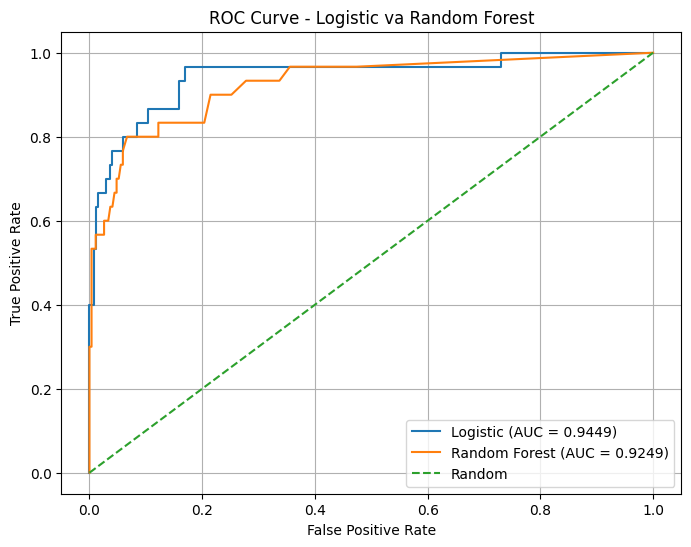

Da luu hinh roc.png


In [ ]:
#bài 4
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score

# Doc du lieu
df = pd.read_csv("data/sinh_vien_bo_hoc.csv")

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# Chia du lieu
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

# Hai mo hinh
logistic = make_pipeline(
    StandardScaler(),
    LogisticRegression()
)

random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=0
)

mo_hinh = {
    "Logistic": logistic,
    "Random Forest": random_forest
}

plt.figure(figsize=(8, 6))

for ten, model in mo_hinh.items():

    model.fit(X_tr, y_tr)

    # Lay xac suat lop 1
    y_score = model.predict_proba(X_te)[:, 1]

    # Tinh ROC va AUC
    fpr, tpr, thresholds = roc_curve(y_te, y_score)
    auc = roc_auc_score(y_te, y_score)

    print(ten, "- AUC:", round(auc, 4))

    plt.plot(
        fpr, tpr,
        label=f"{ten} (AUC = {auc:.4f})"
    )

# Duong doan du doan ngau nhien
plt.plot(
    [0, 1], [0, 1],
    linestyle="--",
    label="Random"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic va Random Forest")
plt.legend()
plt.grid()

# Luu hinh
plt.savefig("roc.png", dpi=300, bbox_inches="tight")
plt.show()

print("Da luu hinh roc.png")

Nhận xét
- Input: Bộ dữ liệu sinh viên với nhãn bo_hoc.
- Phương pháp: Sử dụng Logistic Regression và Random Forest, tính đường ROC và chỉ số AUC.
- Output:
  - Logistic: AUC = 0.9449.
  - Random Forest: AUC = 0.9249.
- Kết quả: Logistic có AUC cao hơn Random Forest 0.0200.
- Giải thích: AUC càng gần 1 thì khả năng phân biệt hai lớp của mô hình càng tốt. Cả hai mô hình đều có khả năng phân loại tốt, nhưng Logistic đạt kết quả cao hơn.
- Kết luận: Logistic là mô hình tốt hơn Random Forest trong thí nghiệm này xét theo chỉ số AUC.

In [ ]:
#bài 5
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score

# Doc du lieu
df = pd.read_csv("data/sinh_vien_bo_hoc.csv")

X = df.drop(columns="bo_hoc")
y = df["bo_hoc"]

# Chia du lieu
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17,
    stratify=y
)

# Tao cac mo hinh truoc va sau can bang
mo_hinh = {
    "RF binh thuong": RandomForestClassifier(
        n_estimators=200,
        random_state=0
    ),

    "RF can bang": RandomForestClassifier(
        n_estimators=200,
        random_state=0,
        class_weight="balanced"
    ),

    "SVC binh thuong": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf")
    ),

    "SVC can bang": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", class_weight="balanced")
    )
}

# Huan luyen va danh gia
ket_qua = {}

for ten, model in mo_hinh.items():

    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)

    precision = precision_score(
        y_te, y_pred, zero_division=0
    )
    recall = recall_score(y_te, y_pred)
    f1 = f1_score(y_te, y_pred)

    ket_qua[ten] = [precision, recall, f1]

    print("\n", ten)
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1:", round(f1, 4))

# So sanh truoc va sau can bang
print("\nMUC DO THAY DOI")

for ten in ["RF", "SVC"]:

    truoc = ket_qua[ten + " binh thuong"]
    sau = ket_qua[ten + " can bang"]

    print("\n", ten)
    print("Precision thay doi:", round(sau[0] - truoc[0], 4))
    print("Recall thay doi:", round(sau[1] - truoc[1], 4))
    print("F1 thay doi:", round(sau[2] - truoc[2], 4))


 RF binh thuong
Precision: 0.7727
Recall: 0.5667
F1: 0.6538

 RF can bang
Precision: 0.75
Recall: 0.4
F1: 0.5217

 SVC binh thuong
Precision: 0.8824
Recall: 0.5
F1: 0.6383

 SVC can bang
Precision: 0.4464
Recall: 0.8333
F1: 0.5814

MUC DO THAY DOI

 RF
Precision thay doi: -0.0227
Recall thay doi: -0.1667
F1 thay doi: -0.1321

 SVC
Precision thay doi: -0.4359
Recall thay doi: 0.3333
F1 thay doi: -0.0569


- Input: Bộ dữ liệu sinh viên có sự mất cân bằng giữa lớp bỏ học và không bỏ học.
- Phương pháp: So sánh Random Forest và SVC trước và sau khi sử dụng class_weight="balanced".
- Output:
  - Mô hình:
    - RF bình thường: Precision: 0.7727, Recall: 0.5667, F1: 0.6538
    - RF cân bằng:	Precision: 0.7500,	Recall: 0.4000,	F1: 0.5217
    - SVC bình thường: 	Precision: 0.8824,	Recall: 0.5000,	F1: 0.6383
    - SVC cân bằng:	Precision: 0.4464,	Recall: 0.8333, F1: 0.5814

- Kết quả:
  - Random Forest sau cân bằng có cả Precision, Recall và F1 đều giảm.
  - SVC sau cân bằng có Recall tăng từ 0.5000 lên 0.8333, nhưng Precision giảm từ 0.8824 xuống 0.4464.
- Giải thích: Cân bằng lớp giúp SVC phát hiện được nhiều sinh viên bỏ học hơn, nhưng đồng thời làm tăng số trường hợp cảnh báo nhầm. Với Random Forest, phương pháp cân bằng không cải thiện kết quả trong lần thử nghiệm này.
- class_weight="balanced" không phải lúc nào cũng cải thiện mọi chỉ số. SVC cân bằng phù hợp khi ưu tiên Recall, còn SVC bình thường có Precision và F1 cao hơn.

In [ ]:

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Doc du lieu gia nha
df = pd.read_csv("data/gia_nha.csv")

print("CAC COT DU LIEU:")
print(df.columns.tolist())

# Tach thuoc tinh va gia nha
X = df.drop(columns="gia")
y = df["gia"]

# Chia du lieu train va test
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y,
    test_size=0.25,
    random_state=17
)

# Huan luyen mo hinh
model = LinearRegression()
model.fit(X_tr, y_tr)

# Du doan
y_pred = model.predict(X_te)

# Ham danh gia
def danh_gia(y_that, y_doan):
    mae = mean_absolute_error(y_that, y_doan)
    rmse = np.sqrt(mean_squared_error(y_that, y_doan))
    r2 = r2_score(y_that, y_doan)

    return mae, rmse, r2

# Ket qua ban dau
mae_1, rmse_1, r2_1 = danh_gia(y_te, y_pred)

print("\nKET QUA BAN DAU")
print("MAE:", round(mae_1, 4))
print("RMSE:", round(rmse_1, 4))
print("R2:", round(r2_1, 4))

# Tao mot du doan sai lech them 5 don vi gia
y_pred_loi = y_pred.copy()
y_pred_loi[0] += 5

# Danh gia lai
mae_2, rmse_2, r2_2 = danh_gia(y_te, y_pred_loi)

print("\nKET QUA SAU KHI THEM SAI SO 5")
print("MAE:", round(mae_2, 4))
print("RMSE:", round(rmse_2, 4))
print("R2:", round(r2_2, 4))

# So sanh
print("\nMUC THAY DOI")
print("MAE thay doi:", round(mae_2 - mae_1, 4))
print("RMSE thay doi:", round(rmse_2 - rmse_1, 4))
print("R2 thay doi:", round(r2_2 - r2_1, 4))


CAC COT DU LIEU:
['dien_tich', 'so_phong', 'tuoi_nha', 'gia']

KET QUA BAN DAU
MAE: 0.2185
RMSE: 0.27
R2: 0.9759

KET QUA SAU KHI THEM SAI SO 5
MAE: 0.5519
RMSE: 1.4433
R2: 0.311

MUC THAY DOI
MAE thay doi: 0.3333
RMSE thay doi: 1.1733
R2 thay doi: -0.6649


Nhận xét:
- Input: Bộ dữ liệu gia_nha.csv gồm 60 mẫu, với 3 thuộc tính đầu vào là dien_tich, so_phong, tuoi_nha và biến mục tiêu gia.
- Phương pháp: Sử dụng thuật toán Linear Regression để dự đoán giá nhà. Dữ liệu được chia thành 75% tập huấn luyện và 25% tập kiểm tra. Sau đó, cố tình cộng thêm 5 đơn vị giá vào một dự đoán để đánh giá ảnh hưởng của sai số lớn đến kết quả mô hình.
- Output: Kết quả ban đầu có MAE = 0.2185, RMSE = 0.2700 và R2 = 0.9759. Sau khi thêm sai số 5 đơn vị, MAE tăng lên 0.5519, RMSE tăng lên 1.4433 và R2 giảm xuống 0.3110.
- Kết quả: MAE tăng 0.3333, RMSE tăng 1.1733 và R2 giảm 0.6649 so với ban đầu. Điều này cho thấy chất lượng đánh giá mô hình giảm đáng kể sau khi xuất hiện một dự đoán có sai số lớn.
- Giải thích: RMSE tăng mạnh hơn MAE vì RMSE tính bình phương sai số trước khi lấy trung bình, khiến chỉ một sai số lớn cũng có thể làm giá trị RMSE tăng đáng kể. Trong khi đó, R2 giảm mạnh từ 0.9759 xuống 0.3110, cho thấy khả năng giải thích sự biến thiên của dữ liệu của mô hình bị suy giảm.
- Kết luận: Một dự đoán sai lệch lớn có thể ảnh hưởng đáng kể đến các chỉ số đánh giá mô hình, đặc biệt là RMSE và R2. Vì vậy, cần kiểm tra và hạn chế các sai số bất thường để đánh giá chính xác chất lượng mô hình Linear Regression.